# LRAT pilot: reproduction and evaluation audit
This notebook reviews an existing AgentCPM-Explore pilot with base Qwen3-Embedding-0.6B and the released LRAT retriever. It runs locally from saved files: no model inference, GPU, cluster connection or corpus download is needed.


## 1. Locate the exported experiment
Put this notebook in `notebooks/` inside the folder containing `runs/`, `indexes/` and the exported Python scripts. Select a local Python kernel and use **Run All**. Existing experiment files are read only; derived reports are written under `analysis/exports/`.

The notebook includes its audit functions, so the `.ipynb` also works with the original extracted input archive. The ready-to-run ZIP includes a separate command-line version of the same audit.

In [1]:
from pathlib import Path
import json
import sys
import html
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

def find_project_root(start):
    start = Path(start).resolve()
    expected = Path('runs/infoseek-20-baseline-v1/judge-localcomm-job-59491/judge-protocol.json')
    for candidate in (start, *start.parents):
        if (candidate / expected).is_file():
            return candidate
    raise FileNotFoundError('Extract lrat-notebook-inputs.tar.gz and place this notebook under that project folder.')

ROOT = find_project_root(Path.cwd())
print('Project:', ROOT.name)
pd.set_option('display.max_colwidth', 95)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.family': 'DejaVu Sans'})

Project: lrat-notebook-project


## 2. Verify the files before interpreting results
Checks cover the 40 frozen trajectory hashes, original/executed evaluator hashes, unchanged judge prompt, identical questions and agent settings, index metadata, shard counts, document-ID mapping, output extraction, and reconstruction of the original correctness calculation.

The export contains **index metadata**, not the index binaries or corpus. Their recorded provenance can be checked here; the 11.2-million-passage vectors themselves cannot be revalidated from this small export.

In [2]:
"""Offline audit of the supplied LRAT pilot. No inference or source-file edits."""

import ast
import csv
import hashlib
import json
import re
from collections import Counter
from pathlib import Path
from statistics import mean

EXPERIMENT = Path('runs/infoseek-20-baseline-v1')
JUDGE_RUN = 'judge-localcomm-job-59491'
INDEX_RUN = Path('indexes/wiki-25-fa2-cacheoff-b512')


def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def canonical_digest(data):
    encoded = json.dumps(data, sort_keys=True, ensure_ascii=False,
                         separators=(',', ':')).encode('utf-8')
    return hashlib.sha256(encoded).hexdigest()


def question_number(qid):
    return int(qid.rsplit('_', 1)[-1])


def official_verdict(text):
    """Exactly the original evaluator's regular expression, including its scope."""
    match = re.search(r'correct:\s*(yes|no)', text or '', re.IGNORECASE)
    return match.group(1).lower() if match else None


def json_fallback_verdict(text):
    """Recover an unambiguous JSON verdict only if the original regex fails."""
    original = official_verdict(text)
    if original is not None:
        return original, 'original_regex'
    decoder = json.JSONDecoder()
    verdicts = set()
    for position, character in enumerate(text or ''):
        if character != '{':
            continue
        try:
            obj, _ = decoder.raw_decode(text[position:])
        except json.JSONDecodeError:
            continue
        if isinstance(obj, dict) and isinstance(obj.get('correct'), str):
            verdict = obj['correct'].strip().lower()
            if verdict in ('yes', 'no'):
                verdicts.add(verdict)
    if len(verdicts) == 1:
        return verdicts.pop(), 'json_fallback'
    return None, 'unresolved'


def extract_answer(output, termination, error=None, retrieval_errors=None):
    """Mirror assess_answer from the archived runner (no finish_reason supplied).

    The exported summaries do not include per-request finish reasons. Existing
    summaries remain authoritative for any additional length-limit annotation.
    """
    text = re.sub(r'<think>.*?</think>', '', output or '', flags=re.DOTALL).strip()
    if error:
        status = 'request_error'
    elif retrieval_errors:
        status = 'retrieval_error'
    elif '<think>' in text:
        status = 'unfinished_thinking'
    else:
        if '</think>' in text:
            text = text.rsplit('</think>', 1)[1].strip()
        if '<tool_call>' in text or '</tool_call>' in text:
            status = 'tool_call_instead_of_answer'
        elif '<answer>' in text and '</answer>' not in text:
            status = 'unfinished_answer'
        else:
            match = re.search(r'<answer>(.*?)</answer>', text, flags=re.DOTALL)
            if match:
                text = match.group(1).strip()
            if not text:
                status = 'empty_answer'
            elif termination not in ('answer', 'generate an answer as token limit reached'):
                status = 'unexpected_termination'
            else:
                status = 'answer_text_present'
    completed = status == 'answer_text_present'
    return {'final_answer': text if completed else '', 'answer_status': status,
            'completed_with_answer': completed}


def judge_template(path):
    """Read the template as an AST literal; never import the GPU evaluator."""
    tree = ast.parse(Path(path).read_text(encoding='utf-8'))
    for node in tree.body:
        if isinstance(node, ast.Assign) and any(
                isinstance(t, ast.Name) and t.id == 'JUDGE_TEMPLATE' for t in node.targets):
            value = node.value
            if isinstance(value, ast.Call) and isinstance(value.func, ast.Attribute) and value.func.attr == 'strip':
                return ast.literal_eval(value.func.value).strip()
            return ast.literal_eval(value)
    raise ValueError('JUDGE_TEMPLATE not found')


def audit_project(project_root):
    root = Path(project_root).resolve()
    folder = root / EXPERIMENT / JUDGE_RUN
    protocol = load_json(folder / 'judge-protocol.json')
    recorded = load_json(folder / 'comparison.json')
    checks = []

    def check(condition, label):
        if not condition:
            raise ValueError('Integrity check failed: ' + label)
        checks.append(label)

    check(sha256(folder / 'official-evaluate.py') == protocol['evaluator_sha256'], 'Original evaluator SHA-256')
    check(sha256(folder / 'evaluate-local-comm.py') == protocol['executed_evaluator_sha256'], 'Executed evaluator SHA-256')
    check(sha256(folder / 'ground-truth.tsv') == protocol['ground_truth_sha256'], 'Ground-truth SHA-256')
    with (folder / 'ground-truth.tsv').open(encoding='utf-8', newline='') as stream:
        gt_rows = list(csv.reader(stream, delimiter='\t', quoting=csv.QUOTE_NONE))
    truth = {row[0].strip(): {'question': row[1].strip(), 'answer': row[2].strip()} for row in gt_rows}
    selected = protocol['selected_questions']
    check(len(truth) == 300, '300 distinct official ground-truth questions')
    check(selected == [[row[0].strip(), row[1].strip()] for row in gt_rows[:20]], 'Pilot is the first 20 official questions')
    check(len(protocol['inputs']) == 40, 'Manifest has 40 frozen inputs')
    check({p.name for p in (folder / 'inputs').glob('*.json')} == set(protocol['inputs']), 'Frozen input filenames match manifest')
    check(load_json(folder / 'communication-test.json')['passed'] is True, 'Two-GPU communication pretest passed')

    indexes = {}
    summaries = {}
    conditions = {}
    rows = []
    cases = {}
    expected_ids = {qid for qid, _ in selected}
    all_results = load_json(folder / 'official-all-results.json')
    all_by_file = {row['file']: row for row in all_results['details']}
    check(len(all_by_file) == 40, 'Official aggregate has 40 distinct outcomes')
    template = judge_template(folder / 'official-evaluate.py')
    check(template == judge_template(folder / 'evaluate-local-comm.py'), 'Judge prompt unchanged in private evaluator copy')

    for name in ('qwen', 'lrat'):
        identity_record = protocol['protocols'][name]
        identity = identity_record['identity']
        check(canonical_digest(identity) == identity_record['identity_sha256'], name + ': agent protocol identity hash')
        check(identity['queries'] == selected, name + ': identical pilot questions')
        check(sha256(root / 'run_infoseek_sample.py') == identity['sample_runner_sha256'], name + ': archived sample-runner hash')
        check(sha256(root / 'run_infoseek_pilot.py') == identity['pilot_helper_sha256'], name + ': archived pilot-helper hash')
        index_path = root / INDEX_RUN / name / 'metadata.json'
        check(sha256(index_path) == identity['index_metadata_sha256'], name + ': index metadata hash')
        indexes[name] = load_json(index_path)
        check(indexes[name]['build_identity']['encoding_run']['corpus_sha256'] == identity['corpus_sha256'], name + ': index/agent corpus hash agreement')
        check(sum(x['rows'] for x in indexes[name]['build_identity']['inputs']) == indexes[name]['documents'], name + ': shard row count agreement')
        summary = load_json(root / EXPERIMENT / name / 'sample-summary.json')
        summaries[name] = summary
        records = {item['query_id']: item for item in summary['results']}
        check(set(records) == expected_ids and summary['processed'] == 20, name + ': all generation outcomes retained')
        check(summary['infrastructure_errors'] == 0, name + ': no reported generation infrastructure errors')
        result = load_json(folder / (name + '-eval.json'))
        check({item['query_id'] for item in result['details']} == expected_ids and len(result['details']) == 20, name + ': 20 judge outcomes')

        for item in sorted(result['details'], key=lambda x: question_number(x['query_id'])):
            qid = item['query_id']
            source = folder / 'inputs' / item['file']
            check(sha256(source) == protocol['inputs'][item['file']]['sha256'], name + '/' + qid + ': frozen trajectory hash')
            check(item == all_by_file[item['file']], name + '/' + qid + ': split and aggregate verdicts agree')
            run = load_json(source)
            record = records[qid]
            output = (run['result'][-1].get('output', '') or '') if run.get('result') else ''
            assessment = extract_answer(output, record['termination'], record['error'], record['retrieval_errors'])
            check(assessment['answer_status'] == record['answer_status'] and assessment['final_answer'] == record['final_answer'] and assessment['completed_with_answer'] == record['completed_with_answer'], name + '/' + qid + ': output extraction agrees with generation summary')
            counts = run.get('tool_call_counts', {}) or {}
            steps = sum(counts.values())
            check(steps == item['steps'] == protocol['inputs'][item['file']]['steps'], name + '/' + qid + ': tool-call counts agree')
            check(counts == record['tool_calls'], name + '/' + qid + ': summary and trajectory tool counts agree')
            old_verdict = official_verdict(item['judge_reason'])
            new_verdict, parse_source = json_fallback_verdict(item['judge_reason'])
            # Preserve the released evaluator's independent unfinished-output guard.
            rejected = output is None or 'tool_call' in output or 'user_query' in output
            official_correct = old_verdict == 'yes' and not rejected
            check(bool(item['correct']) == official_correct, name + '/' + qid + ': reproduce original correctness calculation')
            format_aware = new_verdict == 'yes' and not rejected
            completed = record['completed_with_answer']
            prompt = template.format(question=truth[qid]['question'], response=output,
                                     correct_answer=truth[qid]['answer'])
            row = {
                'retriever': name, 'query_id': qid, 'official_correct': bool(item['correct']),
                'regex_verdict': old_verdict, 'format_aware_verdict': new_verdict,
                'verdict_source': parse_source, 'official_output_rejected': rejected,
                'format_aware_same_guard_correct': format_aware,
                'answer_status': record['answer_status'], 'completed_with_answer': completed,
                'final_answer_gate_diagnostic': bool(item['correct']) and completed,
                'credited_without_final_answer': bool(item['correct']) and not completed,
                'steps': int(steps), 'search_calls': counts.get('search', 0),
                'get_document_calls': counts.get('get_document', 0),
                'generation_seconds': record['seconds'], 'termination': record['termination'],
                'agent_raw_output_chars': len(output), 'final_answer_chars': len(record['final_answer']),
                'judge_output_chars': len(item['judge_reason']),
                'prompt_sha256': hashlib.sha256(prompt.encode('utf-8')).hexdigest(),
            }
            rows.append(row)
            cases[(name, qid)] = {'record': record, 'raw': run, 'judge': item,
                                 'question': truth[qid]['question'], 'reference_answer': truth[qid]['answer'],
                                 'raw_output': output, 'clean_final_answer': record['final_answer'],
                                 'prompt': prompt}

        group = [row for row in rows if row['retriever'] == name]
        metrics = {
            'n': len(group), 'official_correct': sum(x['official_correct'] for x in group),
            'format_aware_same_guard_correct': sum(x['format_aware_same_guard_correct'] for x in group),
            'completed_final_answers': sum(x['completed_with_answer'] for x in group),
            'credited_without_final_answer': sum(x['credited_without_final_answer'] for x in group),
            'final_answer_gate_diagnostic_correct': sum(x['final_answer_gate_diagnostic'] for x in group),
            'unparsed_regex_verdicts': sum(x['regex_verdict'] is None for x in group),
            'unresolved_after_json_fallback': sum(x['format_aware_verdict'] is None for x in group),
            'avg_steps': mean(x['steps'] for x in group),
            'at_50_tool_calls': sum(x['steps'] == 50 for x in group),
            'answer_status_counts': dict(Counter(x['answer_status'] for x in group)),
        }
        check(metrics['official_correct'] == recorded['conditions'][name]['correct'], name + ': recorded success count reproduced')
        check(abs(metrics['avg_steps'] - recorded['conditions'][name]['metrics']['Avg Steps']) < 1e-9, name + ': recorded average steps reproduced')
        conditions[name] = metrics

    qi = protocol['protocols']['qwen']['identity']
    li = protocol['protocols']['lrat']['identity']
    for key in ('protocol', 'queries', 'corpus_sha256', 'source_hashes', 'server_model',
                'server_context_limit', 'agent_config_sha256', 'agent_generation_config', 'agent_weight_files'):
        check(qi[key] == li[key], 'Shared condition: ' + key)
    check(indexes['qwen']['documents'] == indexes['lrat']['documents'], 'Same indexed passage count')
    check(indexes['qwen']['files']['docids.pkl']['sha256'] == indexes['lrat']['files']['docids.pkl']['sha256'], 'Same document-ID mapping hash')

    report = {
        'schema_version': 1, 'source_judge_run': str(EXPERIMENT / JUDGE_RUN),
        'original_files_modified': False, 'inference_performed': False,
        'checks_passed': len(checks), 'conditions': conditions,
        'format_recoveries': [x for x in rows if x['verdict_source'] == 'json_fallback'],
        'credited_without_final_answer': [x for x in rows if x['credited_without_final_answer']],
        'interpretation': {
            'recorded_scores': 'Reproduced original evaluator outputs; not validated final-answer accuracy.',
            'format_audit': 'JSON fallback retains the original independent tool-call/user-query rejection guard.',
            'gate_diagnostic': 'Existing judge labels AND final-answer presence. No clean-answer rejudging was performed; not a replacement accuracy estimate.',
            'next_evaluation': 'Judge cleaned completed final answers only; mark nonanswers failed; retain all 20 questions per condition.',
        },
    }
    return {'root': root, 'folder': folder, 'protocol': protocol, 'recorded': recorded,
            'indexes': indexes, 'summaries': summaries, 'checks': checks, 'rows': rows,
            'cases': cases, 'report': report}


def write_exports(audit, destination):
    """Write derived audit artifacts only. Original experiment files stay intact."""
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    (destination / 'pilot-audit.json').write_text(json.dumps(audit['report'], indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
    with (destination / 'per-question-audit.csv').open('w', encoding='utf-8', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(audit['rows'][0]))
        writer.writeheader()
        writer.writerows(audit['rows'])
    rejudge = []
    for (name, qid), case in sorted(audit['cases'].items(), key=lambda x: (x[0][0], question_number(x[0][1]))):
        record = case['record']
        rejudge.append({
            'retriever': name, 'query_id': qid, 'question': case['question'],
            'reference_answer': case['reference_answer'], 'response': case['clean_final_answer'],
            'requires_judge': record['completed_with_answer'],
            'automatic_failure_reason': None if record['completed_with_answer'] else record['answer_status'],
            'source_file': case['judge']['file'],
        })
    with (destination / 'clean-answer-rejudge-inputs.jsonl').open('w', encoding='utf-8') as stream:
        for record in rejudge:
            stream.write(json.dumps(record, ensure_ascii=False) + '\n')
    return destination

In [3]:
audit = audit_project(ROOT)
protocol = audit['protocol']
report = audit['report']
rows = pd.DataFrame(audit['rows'])
print(f"Passed {report['checks_passed']} integrity and consistency checks.")
print('40 frozen outcomes retained; 20 questions per retriever; original files unchanged.')

summary_rows = []
for name, result in report['conditions'].items():
    summary_rows.append({
        'Retriever': 'Base Qwen' if name == 'qwen' else 'Released LRAT',
        'Recorded correct / 20': result['official_correct'],
        'Recorded evaluator score (%)': 100 * result['official_correct'] / result['n'],
        'Final-answer text present / 20': result['completed_final_answers'],
        'Credited without final answer': result['credited_without_final_answer'],
        'Average tool calls': result['avg_steps'],
    })
summary = pd.DataFrame(summary_rows)
display(summary.style.hide(axis='index').format({
    'Recorded evaluator score (%)': '{:.1f}', 'Average tool calls': '{:.2f}'
}))

Passed 285 integrity and consistency checks.
40 frozen outcomes retained; 20 questions per retriever; original files unchanged.


Retriever,Recorded correct / 20,Recorded evaluator score (%),Final-answer text present / 20,Credited without final answer,Average tool calls
Base Qwen,10,50.0,15,4,44.35
Released LRAT,15,75.0,14,2,39.70


## 3. Experimental setup
The underlying corpus is Wiki-25. Both indexes cover **11,215,099 passages**, with the same corpus hash and document-ID mapping. The pilot uses the **first 20 of 300** official InfoSeek-Eval questions, rather than a random sample.

The agent generates search queries, retrieves top-10 snippets and can open full passages. The two conditions change the retriever checkpoint. The corpus, question set, agent model/configuration and declared agent protocol match.

In [4]:
model_rows = []
for name, index in audit['indexes'].items():
    build = index['build_identity']
    encoding = build['encoding_run']
    model_rows.append({
        'Condition': name,
        'Retriever checkpoint': encoding['model']['repo'],
        'Revision': encoding['model']['revision'],
        'Passages': index['documents'],
        'Dimensions': index['dimension'],
        'Index': build['index_type'],
        'Index size (GiB)': index['files']['index.faiss']['bytes'] / 2**30,
    })
display(pd.DataFrame(model_rows).style.hide(axis='index').format({
    'Passages': '{:,}', 'Index size (GiB)': '{:.2f}'
}))

identity = protocol['protocols']['qwen']['identity']
agent_settings = identity['protocol']
keys = ['temperature', 'top_p', 'presence_penalty', 'seed', 'k', 'snippet_max_tokens',
        'document_max_tokens', 'max_main_loop_calls', 'query_max_length', 'normalize']
settings = [{'Setting': key, 'Value': str(agent_settings[key])} for key in keys]
settings.insert(0, {'Setting': 'Agent', 'Value': 'AgentCPM-Explore'})
settings.append({'Setting': 'Agent server context ceiling', 'Value': str(identity['server_context_limit'])})
display(pd.DataFrame(settings).style.hide(axis='index'))

Condition,Retriever checkpoint,Revision,Passages,Dimensions,Index,Index size (GiB)
qwen,Qwen/Qwen3-Embedding-0.6B,97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3,"11,215,099",1024,IndexFlatIP,42.78
lrat,Yuqi-Zhou/LRAT-Qwen3-Embedding-0.6B,81c339a83d4407454e59c8069b0720493e3451a6,"11,215,099",1024,IndexFlatIP,42.78


Setting,Value
Agent,AgentCPM-Explore
temperature,0.85
top_p,0.95
presence_penalty,1.1
seed,2025
k,10
snippet_max_tokens,64
document_max_tokens,512
max_main_loop_calls,50
query_max_length,8192


### Agent settings and judge settings are different
The judge receives the question, the candidate response and the reference answer in the released `JUDGE_TEMPLATE`. In this saved run, the evaluator used the **last raw agent output**, which can contain reasoning or a tool call. It did not reliably restrict judging to a completed final answer. The audit later shows why that matters.

The private evaluator retains the original prompt. Its output budget was increased from 512 to 4,096 tokens. Same-node communication settings and `disable_custom_all_reduce=True` were used to start the model on two L40S GPUs. These are documented execution changes, not an exact reproduction of every released runtime setting.

In [5]:
judge_settings = protocol['evaluation_settings']
judge_rows = [
    ('Judge checkpoint', protocol['judge']['model']),
    ('Judge revision', protocol['judge']['revision']),
    ('Temperature', judge_settings['temperature']),
    ('Seed', judge_settings['seed']),
    ('Released evaluator output budget', judge_settings['official_max_tokens']),
    ('This run: output budget', judge_settings['max_tokens']),
    ('This run: context ceiling', protocol['execution_workaround']['max_model_len']),
    ('Tensor-parallel GPUs', judge_settings['tensor_parallel_size']),
    ('GPU memory utilization', judge_settings['gpu_memory_utilization']),
    ('Judge batch size', judge_settings['batch_size']),
    ('GPUs', ', '.join(protocol['runtime']['gpus'])),
    ('vLLM', protocol['runtime']['vllm']),
    ('Prompt handling', judge_settings['prompt']),
]
display(pd.DataFrame(judge_rows, columns=['Setting', 'Value']).astype(str).style.hide(axis='index'))

Setting,Value
Judge checkpoint,Qwen/Qwen3-30B-A3B-Thinking-2507
Judge revision,144afc2f379b542fdd4e85a1fcd5e1f79112d95d
Temperature,0.0
Seed,2026
Released evaluator output budget,512
This run: output budget,4096
This run: context ceiling,65536
Tensor-parallel GPUs,2
GPU memory utilization,0.9
Judge batch size,32


### Check that the 65,536-token ceiling preserves the saved inputs
The raw prompts were reconstructed and tokenized with the pinned judge checkpoint's `tokenizer.json`. The precomputed token-count audit is included below; each count is tied to the reconstructed prompt by SHA-256. Running this notebook verifies those prompt hashes without downloading a tokenizer.

This checks input capacity, not whether every judge response finished naturally: judge finish reasons were not retained by the original evaluator.

In [6]:
PROMPT_LENGTH_AUDIT = {'model': 'Qwen/Qwen3-30B-A3B-Thinking-2507', 'revision': '144afc2f379b542fdd4e85a1fcd5e1f79112d95d', 'tokenizer_json_sha256': '19564a48c4f71a2a1b937cce34c737a1e662b171c5f5d7edf641a15cd896f07d', 'tokenizer_config_sha256': '9c9cfea24361f234a5ef67d3f49f69733163f77c0d1fcced5b5aa72913b8ea22', 'tokenizers_version': '0.23.3', 'method': 'Exact raw JUDGE_TEMPLATE prompts; pinned Qwen tokenizer.json; add_special_tokens=True (same IDs count as False); no chat template.', 'max_model_len': 65536, 'rows': [{'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_0', 'prompt_sha256': '015c66c06d45051eafd55a2414fa6f861272dba59e6b6f8027ee8d07e8922d4c', 'prompt_tokens': 2277, 'reserved_output_tokens': 4096, 'combined_tokens': 6373, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_1', 'prompt_sha256': '6e2cd7e8eb0479ceda303686a35924305d9a157e729a9c41fff76f8d72aef2b1', 'prompt_tokens': 4711, 'reserved_output_tokens': 4096, 'combined_tokens': 8807, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_2', 'prompt_sha256': 'daffbb6cf9225265cd69b8adf3d80c0076b07d5c70f8dc3d877d05f34fba9144', 'prompt_tokens': 1847, 'reserved_output_tokens': 4096, 'combined_tokens': 5943, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_3', 'prompt_sha256': '4a6859d291945785864ccda07ef76df1295011f38353b46cb33137ec3e5bc64a', 'prompt_tokens': 770, 'reserved_output_tokens': 4096, 'combined_tokens': 4866, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_4', 'prompt_sha256': 'de24c8b5ccfdf9962d04aeca495a0b7495292879f52786635875798fb80ebc55', 'prompt_tokens': 5446, 'reserved_output_tokens': 4096, 'combined_tokens': 9542, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_5', 'prompt_sha256': '1d4f065102647edcac5b00a6b461b6f978784b5166296e71be7a2b299282421d', 'prompt_tokens': 760, 'reserved_output_tokens': 4096, 'combined_tokens': 4856, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_6', 'prompt_sha256': '2d8279cd90da51d6679172ef7d1e1a782335e4d3e5006778be994c1324c00ed9', 'prompt_tokens': 712, 'reserved_output_tokens': 4096, 'combined_tokens': 4808, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_7', 'prompt_sha256': '3af4214f021db19489745d27b068a77b971af7c3c2d41805babaa6fb0233d5e2', 'prompt_tokens': 1087, 'reserved_output_tokens': 4096, 'combined_tokens': 5183, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_8', 'prompt_sha256': 'bbab2cdddec3105b334732658087d6421b8750080edcc55e305b14f3d0439183', 'prompt_tokens': 891, 'reserved_output_tokens': 4096, 'combined_tokens': 4987, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_9', 'prompt_sha256': 'cb85f6c14c5ee4b88c8a912e599b71815c92a8eab0be2b30b1eae61ac85cd56e', 'prompt_tokens': 736, 'reserved_output_tokens': 4096, 'combined_tokens': 4832, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_10', 'prompt_sha256': '87393c7eec3b9b684c055044207f25e2459eeb751e7bca29762dee7ba3646867', 'prompt_tokens': 506, 'reserved_output_tokens': 4096, 'combined_tokens': 4602, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_11', 'prompt_sha256': '8c209b51ea5a4b5b8bffb4bc4537a9bb8f348c7b41b9d0b49b4aa1278d1774e3', 'prompt_tokens': 860, 'reserved_output_tokens': 4096, 'combined_tokens': 4956, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_12', 'prompt_sha256': 'a52047a327a0305e5077e09964dcb573fa50bea1ebf85460169b33ba8f5884f3', 'prompt_tokens': 9329, 'reserved_output_tokens': 4096, 'combined_tokens': 13425, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_13', 'prompt_sha256': 'a7d91518de20707ea8250840f2a239d2a7fb23a1411e92cc9e0d190fe9c4b3cb', 'prompt_tokens': 2431, 'reserved_output_tokens': 4096, 'combined_tokens': 6527, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_14', 'prompt_sha256': 'ed86ddc022f5270c0a555ccd4eee380391324815c197f57be34fd7ccca07b13a', 'prompt_tokens': 2478, 'reserved_output_tokens': 4096, 'combined_tokens': 6574, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_15', 'prompt_sha256': '7f2563fbd654ee85c18bcd19a0aa3b8a6b4f57069c8e8ee57d8b5981825f6105', 'prompt_tokens': 920, 'reserved_output_tokens': 4096, 'combined_tokens': 5016, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_16', 'prompt_sha256': '49e5ca9d4f7d920b724766a6b06b5dc09d82c6fad7654e17c17fd22c897ab375', 'prompt_tokens': 10362, 'reserved_output_tokens': 4096, 'combined_tokens': 14458, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_17', 'prompt_sha256': 'bd4d7b73eaa5fc36cbbf7ce2fd67785e298b9ebced09a48479635a7357c3f5da', 'prompt_tokens': 663, 'reserved_output_tokens': 4096, 'combined_tokens': 4759, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_18', 'prompt_sha256': 'a15f1276d32522324259105bd50175aea92285f33bfae8a334f63eea32bbfab3', 'prompt_tokens': 891, 'reserved_output_tokens': 4096, 'combined_tokens': 4987, 'within_context_limit': True}, {'retriever': 'qwen', 'query_id': 'InfoSeek-Eval_19', 'prompt_sha256': 'e72c39348e946b9632bb968db8e7fd14b6c678a85434ed90fb3dcf8112c77529', 'prompt_tokens': 1259, 'reserved_output_tokens': 4096, 'combined_tokens': 5355, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_0', 'prompt_sha256': 'efeb8ed98d721bf2f98d39310277512ab487c214ab6470fe775807e61bb18bb7', 'prompt_tokens': 945, 'reserved_output_tokens': 4096, 'combined_tokens': 5041, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_1', 'prompt_sha256': '25f2dd4477e2deb02a2c080ab4f6d7963a76d7f43f270427b9614039691f51cf', 'prompt_tokens': 1226, 'reserved_output_tokens': 4096, 'combined_tokens': 5322, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_2', 'prompt_sha256': '6e761a08be03c4a36006252c92d222e924b84e820b88afabc6984083a157a524', 'prompt_tokens': 1331, 'reserved_output_tokens': 4096, 'combined_tokens': 5427, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_3', 'prompt_sha256': 'e86ad9cc4ab3ea3c881c2425b9252414c0efc326e4ef1251eea03cc50cedb659', 'prompt_tokens': 523, 'reserved_output_tokens': 4096, 'combined_tokens': 4619, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_4', 'prompt_sha256': 'fb9350a955ef29da4d30e56ebaac3580b45d1ea01e8340c06aaf778b029532f4', 'prompt_tokens': 10383, 'reserved_output_tokens': 4096, 'combined_tokens': 14479, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_5', 'prompt_sha256': '49d9dc14be2d6dadbe2f4039345a07ebc349f749e62728adfb3ce044680aad8a', 'prompt_tokens': 754, 'reserved_output_tokens': 4096, 'combined_tokens': 4850, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_6', 'prompt_sha256': '95bfdf398aefa1b919857e833738badb3302002a52b6221edcafb42350f67b7a', 'prompt_tokens': 544, 'reserved_output_tokens': 4096, 'combined_tokens': 4640, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_7', 'prompt_sha256': '7a391c810971781b83a48a4a99a43e0455e3c8e5f449eb791c4377bfc58bda5e', 'prompt_tokens': 623, 'reserved_output_tokens': 4096, 'combined_tokens': 4719, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_8', 'prompt_sha256': '491e8ae4d0a08ec33b8b22e13d826843672a593072049efdf4232d4b4dca57da', 'prompt_tokens': 860, 'reserved_output_tokens': 4096, 'combined_tokens': 4956, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_9', 'prompt_sha256': '7a8f36108fdf79ee88539a8dbfedeb7fb3e248a6341ef72acabb4aeef241e969', 'prompt_tokens': 648, 'reserved_output_tokens': 4096, 'combined_tokens': 4744, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_10', 'prompt_sha256': '3a74c77fbb310733ac5d5acbbc751e513717247278e4b00683bac079d7a62551', 'prompt_tokens': 520, 'reserved_output_tokens': 4096, 'combined_tokens': 4616, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_11', 'prompt_sha256': 'fb8fba630f0d757e84c8e4946a14bb9b67530aafa0c1f3ed9a8129d9f9af8456', 'prompt_tokens': 678, 'reserved_output_tokens': 4096, 'combined_tokens': 4774, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_12', 'prompt_sha256': 'dbd2f47fd49f6044f0ce6675c0027999e47c9978f3848a3b542d2397ec237d56', 'prompt_tokens': 666, 'reserved_output_tokens': 4096, 'combined_tokens': 4762, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_13', 'prompt_sha256': '627caa9eb79b02d886c7fd54319f8ca3b742b12838389eeaa740414685e94faa', 'prompt_tokens': 5216, 'reserved_output_tokens': 4096, 'combined_tokens': 9312, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_14', 'prompt_sha256': 'abfc8fb9d00c4d87bd1f936ca6124dabefee49ecbb47dda1a603463770b06aea', 'prompt_tokens': 2819, 'reserved_output_tokens': 4096, 'combined_tokens': 6915, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_15', 'prompt_sha256': '5d758ad386cf4a467ca0a0a9dcd44d36d29d3ca559b7327f4d0a26918ad4f616', 'prompt_tokens': 868, 'reserved_output_tokens': 4096, 'combined_tokens': 4964, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_16', 'prompt_sha256': '65546635ca85e1c93ff07badb8a052ed19ac41f1f3040b32d3b5932fe1f81bde', 'prompt_tokens': 634, 'reserved_output_tokens': 4096, 'combined_tokens': 4730, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_17', 'prompt_sha256': 'e5c163850c20ba96256045d16d7794e80e00e8fc87c448330cbc39eecf58c6bf', 'prompt_tokens': 768, 'reserved_output_tokens': 4096, 'combined_tokens': 4864, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_18', 'prompt_sha256': '463bf84231a8bb3fb84c9eaa5c0238107c30f062a57dbdc04414e8cb94f7cec1', 'prompt_tokens': 899, 'reserved_output_tokens': 4096, 'combined_tokens': 4995, 'within_context_limit': True}, {'retriever': 'lrat', 'query_id': 'InfoSeek-Eval_19', 'prompt_sha256': 'febb66bb20b2305135cbfb0d81d9d1407e904a4f6056a3038283e14b6458ce38', 'prompt_tokens': 415, 'reserved_output_tokens': 4096, 'combined_tokens': 4511, 'within_context_limit': True}]}

In [7]:
token_rows = pd.DataFrame(PROMPT_LENGTH_AUDIT['rows'])
for row in token_rows.to_dict('records'):
    actual = next(x for x in audit['rows'] if x['retriever'] == row['retriever'] and x['query_id'] == row['query_id'])
    assert row['prompt_sha256'] == actual['prompt_sha256']
    assert row['prompt_tokens'] + judge_settings['max_tokens'] <= protocol['execution_workaround']['max_model_len']
token_summary = token_rows.groupby('retriever')['prompt_tokens'].agg(['min', 'max'])
token_summary['Output budget'] = judge_settings['max_tokens']
token_summary['Largest input + output'] = token_summary['max'] + judge_settings['max_tokens']
token_summary['Context ceiling'] = protocol['execution_workaround']['max_model_len']
display(token_summary)
print('All 40 raw prompts fit with the full 4,096-token output allowance.')
print('Tokenizer revision:', PROMPT_LENGTH_AUDIT['revision'])

,min,max,Output budget,Largest input + output,Context ceiling
retriever,,,,,
lrat,415,10383,4096,14479,65536
qwen,506,10362,4096,14458,65536


All 40 raw prompts fit with the full 4,096-token output allowance.
Tokenizer revision: 144afc2f379b542fdd4e85a1fcd5e1f79112d95d


## 4. Recorded results and generation outcomes
The first panel reproduces saved evaluator labels. It is not a claim of validated answer accuracy. The completion panel independently counts outputs that contain final-answer text after removing reasoning. All 20 questions, including generation failures, remain in each denominator.

Average steps are total recorded `search` plus `get_document` calls per question, across successful and failed outcomes. Many questions reach the 50-call limit. Timing comparisons are not treated as controlled hardware benchmarks.

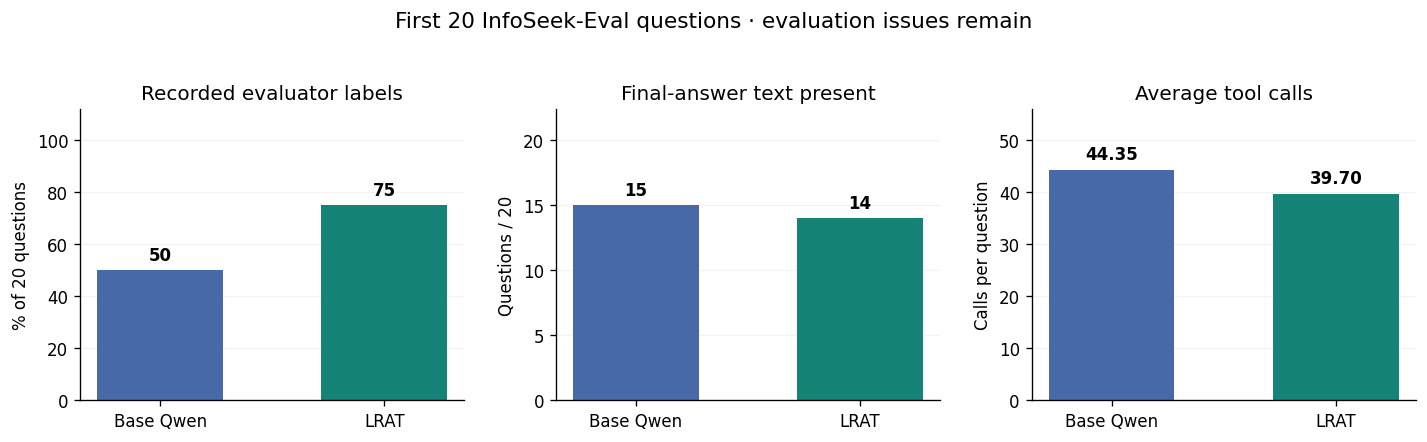

retriever,qwen,lrat
answer_status,,
answer_text_present,15,14
empty_answer,3,2
tool_call_instead_of_answer,1,3
unfinished_thinking,1,1


Questions at 50 tool calls: {'qwen': 17, 'lrat': 12}


In [8]:
names = ['qwen', 'lrat']
labels = ['Base Qwen', 'LRAT']
colors = ['#4869A7', '#168378']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
specs = [
    ('Recorded evaluator labels', [100 * report['conditions'][n]['official_correct'] / 20 for n in names], '% of 20 questions', 100),
    ('Final-answer text present', [report['conditions'][n]['completed_final_answers'] for n in names], 'Questions / 20', 20),
    ('Average tool calls', [report['conditions'][n]['avg_steps'] for n in names], 'Calls per question', 50),
]
for ax, (title, values, ylabel, ceiling) in zip(axes, specs):
    bars = ax.bar(labels, values, color=colors, width=0.56)
    ax.set(title=title, ylabel=ylabel, ylim=(0, ceiling * 1.12))
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.15)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + ceiling * 0.025,
                f'{value:.2f}' if title == 'Average tool calls' else f'{value:g}',
                ha='center', va='bottom', fontweight='bold')
fig.suptitle('First 20 InfoSeek-Eval questions · evaluation issues remain', fontsize=13, y=1.04)
fig.tight_layout()
export_dir = ROOT / 'analysis/exports'
export_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(export_dir / 'pilot-overview.png', dpi=180, bbox_inches='tight')
plt.show()

status_table = pd.crosstab(rows['answer_status'], rows['retriever']).reindex(columns=names, fill_value=0)
display(status_table)
print('Questions at 50 tool calls:', {n: report['conditions'][n]['at_50_tool_calls'] for n in names})

## 5. Why recovering the JSON verdict does not produce 80%
For `lrat / InfoSeek-Eval_13`, the judge returned `"correct": "yes"` in JSON. The released regex expects `correct: yes`, so it did not parse that verdict.

However, the evaluator also independently rejects an agent output containing `tool_call` or `user_query`. The actual output for this question ends in another search tool call and has **no completed final answer**. Recovering the JSON verdict while preserving this guard keeps the outcome incorrect.

**Therefore, 16/20 (80%) is not a justified correction.** The recorded count remains 15/20 even when JSON verdicts are recognized. The judge's claimed extracted answer is also absent from this raw output as a literal string.

In [9]:
case = audit['cases'][('lrat', 'InfoSeek-Eval_13')]
case_row = next(x for x in audit['rows'] if x['retriever'] == 'lrat' and x['query_id'] == 'InfoSeek-Eval_13')
display(pd.DataFrame([{
    'JSON verdict': case_row['format_aware_verdict'],
    'Agent status': case_row['answer_status'],
    'Final-answer characters': case_row['final_answer_chars'],
    'Original rejection guard': case_row['official_output_rejected'],
    'Correct after format recovery + same guard': case_row['format_aware_same_guard_correct'],
}]).style.hide(axis='index'))
print('END OF ACTUAL AGENT OUTPUT:\n' + case['raw_output'][-850:])
print('\nSAVED JUDGE RESPONSE:\n' + case['judge']['judge_reason'])

JSON verdict,Agent status,Final-answer characters,Original rejection guard,Correct after format recovery + same guard
yes,tool_call_instead_of_answer,0,True,False


END OF ACTUAL AGENT OUTPUT:
ger moth that feeds on tomatoes and was introduced via import of tomato seedlings. For example, "Tomato leafroller" (Phaedropsocus coccae) is a larva of a moth (family Gelechiidae) that feeds on leaves and stems of tomatoes. Its wingspan might be around 20-34 mm? Let's check.

We haven't looked at "Phaedropsocus coccae". It is a moth (family Gelechiidae) that larvae are leaf miners and stem borers of tomatoes. Let's search for "Phaedropsocus coccae".

We did not do that.

Let's try to search for "tomato leafroller moth Europe".

We did that and got "Phaedropsocus coccae"? Actually, we found "Phaedropsocus coccae" in a search for "tomato leafroller moth"? Not sure.

But we can try to search for "Phaedropsocus coccae".

Let's do that.
</think>

<tool_call>
{"name": "search", "arguments": {"query": ["\"Phaedropsocus coccae\""]}}
</tool_call>

SAVED JUDGE RESPONSE:
 If the confidence score is not available, use 100.

[response] is correct if and only if:
- The e

## 6. More consequential issue: credit without a final answer
The saved labels mark **four Qwen runs and two LRAT runs correct even though the generation summary and independent extraction agree that no final answer exists**. The evaluator sends raw reasoning to a judge that also sees the reference answer. Some judge responses then claim the reference was extracted from an output that never supplied it.

The table below is a diagnostic, not a new validated score. Its last column keeps an existing positive label only when a final answer is present. It does not rejudge that cleaned final answer, so it cannot establish the final answer's correctness.

In [10]:
flagged = rows.loc[rows['credited_without_final_answer'],
                   ['retriever', 'query_id', 'answer_status', 'final_answer_chars', 'official_correct']]
display(flagged.reset_index(drop=True))

diagnostics = []
for name, result in report['conditions'].items():
    diagnostics.append({
        'Condition': name,
        'Recorded evaluator positives': result['official_correct'],
        'Positives without a final answer': result['credited_without_final_answer'],
        'Remaining positives after presence gate (diagnostic only)': result['final_answer_gate_diagnostic_correct'],
    })
display(pd.DataFrame(diagnostics).style.hide(axis='index'))
display(Markdown('**Required repair:** rejudge only cleaned completed final answers; count nonanswers as failures and keep the full 20-question denominator.'))

,retriever,query_id,answer_status,final_answer_chars,official_correct
0,qwen,InfoSeek-Eval_8,empty_answer,0,True
1,qwen,InfoSeek-Eval_10,empty_answer,0,True
2,qwen,InfoSeek-Eval_16,unfinished_thinking,0,True
3,qwen,InfoSeek-Eval_17,empty_answer,0,True
4,lrat,InfoSeek-Eval_3,empty_answer,0,True
5,lrat,InfoSeek-Eval_10,empty_answer,0,True


Condition,Recorded evaluator positives,Positives without a final answer,Remaining positives after presence gate (diagnostic only)
qwen,10,4,6
lrat,15,2,13


**Required repair:** rejudge only cleaned completed final answers; count nonanswers as failures and keep the full 20-question denominator.

In [11]:
case = audit['cases'][('qwen', 'InfoSeek-Eval_8')]
print('QUESTION:', case['question'])
print('\nREFERENCE:', case['reference_answer'])
print('\nCLEAN FINAL ANSWER:', repr(case['clean_final_answer']))
print('\nFULL LAST AGENT OUTPUT:\n' + case['raw_output'])
print('\nJUDGE RESPONSE END:\n' + case['judge']['judge_reason'][-1100:])

QUESTION: Who is a sport official who competed in the 1912 Summer Olympics and finished 22nd in the javelin throw? This person received the Military Order of Max Joseph in 1921.

REFERENCE: Karl Ritter von Halt

CLEAN FINAL ANSWER: ''

FULL LAST AGENT OUTPUT:
<think>
We are looking for a sport official who competed in the 1912 Summer Olympics and finished 22nd in the javelin throw, and who received the Military Order of Max Joseph in 1921.

From the search results, we see that the men's javelin throw event at the 1912 Summer Olympics had Julius Saaristo (Finland) and Eric Lemming (Sweden) as top competitors. However, we need to find a competitor who finished 22nd in this event.

We also note that the Military Order of Max Joseph is a Bavarian order, so the recipient was likely from Bavaria or German-speaking region.

Let's try to find a list of all participants and their placements in the 1912 men's javelin throw. The search results did not show the full ranking. We might need to look 

## 7. Inspect a genuine paired example
`InfoSeek-Eval_1` has final-answer text in both conditions. The base Qwen run names Ion I. C. Brătianu; the LRAT run names Ion Ghica, the provided reference. This is an illustrative case selected after inspecting the outcomes, rather than independent evidence of general superiority.

The helper below can inspect any of the 20 questions. Set `limit=None` to show the complete saved output. It reads the existing trajectories rather than rerunning the agent.

In [12]:
def show_case(retriever, number, limit=1100):
    qid = f'InfoSeek-Eval_{number}'
    case = audit['cases'][(retriever, qid)]
    record = case['record']
    answer = case['clean_final_answer']
    shown = answer if limit is None else answer[:limit]
    suffix = '' if limit is None or len(answer) <= limit else '\n[Display excerpt; full text is saved in the trajectory.]'
    display(Markdown(f"### {retriever} · {qid}"))
    display(Markdown(f"**Reference:** {case['reference_answer']}  \n**Status:** {record['answer_status']}  \n**Recorded tool calls:** {sum(record['tool_calls'].values())}"))
    display(HTML('<pre style="white-space:pre-wrap;line-height:1.5">' + html.escape(shown + suffix) + '</pre>'))

show_case('qwen', 1)
show_case('lrat', 1)

### qwen · InfoSeek-Eval_1

**Reference:** Ion Ghica  
**Status:** answer_text_present  
**Recorded tool calls:** 50

### lrat · InfoSeek-Eval_1

**Reference:** Ion Ghica  
**Status:** answer_text_present  
**Recorded tool calls:** 45

### Per-question view
`Recorded correct` reflects the original evaluator output. `Final answer present` is an independent generation check. These columns should not be conflated.

In [13]:
paired = []
for qid, _ in protocol['selected_questions']:
    pair = {'Question': qid}
    for name in names:
        row = next(x for x in audit['rows'] if x['retriever'] == name and x['query_id'] == qid)
        pair[name + ': recorded correct'] = row['official_correct']
        pair[name + ': final answer present'] = row['completed_with_answer']
        pair[name + ': tool calls'] = row['steps']
    paired.append(pair)
display(pd.DataFrame(paired).style.hide(axis='index'))

Question,qwen: recorded correct,qwen: final answer present,qwen: tool calls,lrat: recorded correct,lrat: final answer present,lrat: tool calls
InfoSeek-Eval_0,False,True,50,False,False,50
InfoSeek-Eval_1,False,True,50,True,True,45
InfoSeek-Eval_2,False,True,50,False,True,38
InfoSeek-Eval_3,True,True,50,True,False,50
InfoSeek-Eval_4,False,True,50,False,False,50
InfoSeek-Eval_5,False,False,50,True,True,50
InfoSeek-Eval_6,False,True,22,True,True,7
InfoSeek-Eval_7,True,True,11,True,True,50
InfoSeek-Eval_8,True,False,50,True,True,45
InfoSeek-Eval_9,True,True,50,True,True,36


## 8. Export the audit and clean inputs for the next judging pass
This cell writes derived files only:

- `pilot-audit.json`: checks, recorded metrics and identified issues.
- `per-question-audit.csv`: the full 40-outcome audit table.
- `clean-answer-rejudge-inputs.jsonl`: all 40 outcomes with cleaned final answers. `requires_judge` is true only for completed final answers; the other outcomes have an automatic failure reason.

No new correctness labels are created here. Judge the completed answers in a subsequent GPU job using one documented protocol for both retrievers. Store the response finish reason, generated token count and final structured verdict; unresolved verdicts should be inspected, rather than silently treated as semantic failures.

In [14]:
destination = write_exports(audit, ROOT / 'analysis/exports')
rejudge_rows = [json.loads(line) for line in (destination / 'clean-answer-rejudge-inputs.jsonl').read_text().splitlines()]
display(pd.DataFrame(rejudge_rows).groupby('retriever')['requires_judge'].agg(['sum', 'count']).rename(
    columns={'sum': 'Completed answers to judge', 'count': 'Total questions retained'}))
print('Derived reports written to analysis/exports/.')
print('Original evaluator outputs remain unchanged.')

,Completed answers to judge,Total questions retained
retriever,,
lrat,14,20
qwen,15,20


Derived reports written to analysis/exports/.
Original evaluator outputs remain unchanged.


## 9. Position relative to the LRAT paper
Table 2 of [Learning to Retrieve from Agent Trajectories](https://arxiv.org/html/2604.04949v1) reports the following AgentCPM-Explore + Qwen3-Embedding-0.6B results on **all 300** InfoSeek-Eval questions:

| Retriever | Reported success rate | Reported average steps |
|---|---:|---:|
| Base Qwen3-Embedding-0.6B | 40.3% | 38.0 |
| LRAT-Qwen3-Embedding-0.6B | 55.7% | 34.4 |

Those published values are a reference, not directly matched reproduction targets for this first-20 pilot. The current export also uses a longer judge output budget, a recorded runtime workaround and a raw-output judging path with the issues shown above. A JSON-aware parser does not resolve the final-answer extraction problem.

The pilot establishes that the saved experimental artifacts can be analysed and checked locally. A numerical reproduction claim should wait for repaired judging and the agreed full evaluation.